# 09 — Forecast combinations

**Question.** Does machine learning forecast NDVI one month ahead better than a seasonal
ARIMA specified in advance, and which model should forecast each component of the series?

Machine-learning forecasts of vegetation are usually compared with persistence or linear
regression, references that do not model the seasonal cycle. In the large forecasting
competitions, well-specified statistical models are often as accurate as machine learning,
or more (Makridakis et al., 2018), so the reference here is a seasonal ARIMA whose orders
are fixed by a rule before any other model is fitted (Box et al., 2015).

The series is also split into a seasonal and a trend component, each component is forecast
by its own model, and the two forecasts are added: a component-wise hybrid in the spirit of
Zhang (2003) and of the wavelet framework of notebooks 02–05. Every pairing of a seasonal and
a trend model is evaluated.

| Role | Models |
|---|---|
| reference | SARIMA; SARIMAX with the lagged climate predictors of notebook 03 |
| linear floor | Ridge regression: linear, sees the season only through lags and the calendar |
| nonlinear | support vector regression (SVR), a small neural network (MLP), XGBoost, Random Forest |

| Decomposition | Trend | Seasonal | Uses later months |
|---|---|---|---|
| wavelet | discrete Meyer approximation (notebook 02) | series − trend | yes |
| causal | trailing 12-month mean (notebook 02) | series − trend | no |

**Design.** Five forecast origins, each followed by a three-year window (2010–12, 2013–15,
2016–18, 2019–21, 2022–24); the last window, a period of severe drought, is the test period.
At every origin, everything is decided on the months before it: SARIMA orders, the
hyperparameters of every model, and the pairing of seasonal and trend models. No window
therefore informs any choice used to forecast it (Tashman, 2000).

Input: `data/processed/features_*.csv`, `data/raw/` · Output: `results/09_*`, `figures/09_*`

In [1]:
import json
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning as SMConvergenceWarning
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from xgboost import XGBRegressor

# statsmodels warns on fits whose optimiser stops early or whose start values are
# non-stationary; such fits are kept, and fits that fail are caught where they are made
for w in (ConvergenceWarning, SMConvergenceWarning, UserWarning, RuntimeWarning, FutureWarning):
    warnings.filterwarnings("ignore", category=w)

SEED = 0
N_ITER = 100
WINDOWS = [("2010-01-01", "2012-12-01"), ("2013-01-01", "2015-12-01"),
           ("2016-01-01", "2018-12-01"), ("2019-01-01", "2021-12-01"),
           ("2022-01-01", "2024-12-01")]
TEST = "2022-24"

FILES = {("direct", "original"): "original",
         ("wavelet", "seasonal"): "seasonal", ("wavelet", "trend"): "trend",
         ("causal", "seasonal"): "causal_seasonal", ("causal", "trend"): "causal_trend"}
frames = {k: pd.read_csv(f"../data/processed/features_{f}.csv", index_col="date",
                         parse_dates=True).asfreq("MS") for k, f in FILES.items()}

# one sample for every series: all start where the latest one can
start = max(df.dropna().index[0] for df in frames.values())
DATA = {k: df[df.index >= start].drop(columns="split") for k, df in frames.items()}
ndvi = DATA[("direct", "original")]["target"]

for dec in ["wavelet", "causal"]:
    gap = (DATA[(dec, "seasonal")].target + DATA[(dec, "trend")].target - ndvi).abs().max()
    print(f"{dec}: seasonal + trend reproduces NDVI to {gap:.1e}")
for key, df in DATA.items():
    print(f"{'/'.join(key):17s} {df.shape[1] - 1:2d} predictors, "
          f"{df.index[0]:%Y-%m} to {df.index[-1]:%Y-%m}")

wavelet: seasonal + trend reproduces NDVI to 2.2e-16
causal: seasonal + trend reproduces NDVI to 1.7e-16
direct/original   14 predictors, 2003-02 to 2024-12
wavelet/seasonal  17 predictors, 2003-02 to 2024-12
wavelet/trend      6 predictors, 2003-02 to 2024-12
causal/seasonal   18 predictors, 2003-02 to 2024-12
causal/trend      10 predictors, 2003-02 to 2024-12


## The two decompositions

The wavelet trend is smooth because it is centred: each value averages months on both
sides. The trailing mean lags behind turning points by about half a year, and its seasonal
component keeps more of the year-to-year variation.

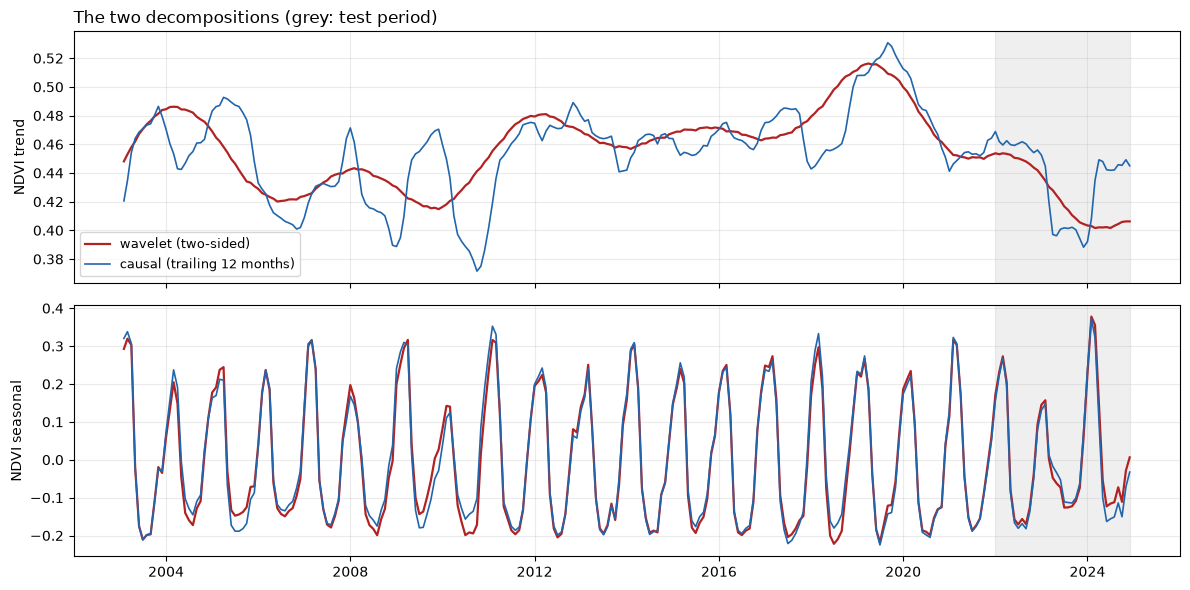

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, part in zip(axes, ["trend", "seasonal"]):
    ax.plot(DATA[("wavelet", part)].target, color="firebrick", lw=1.6, label="wavelet (two-sided)")
    ax.plot(DATA[("causal", part)].target, color="#2166ac", lw=1.2, label="causal (trailing 12 months)")
    ax.axvspan(pd.Timestamp(WINDOWS[-1][0]), ndvi.index[-1], color="grey", alpha=0.12, zorder=0)
    ax.set_ylabel(f"NDVI {part}")
    ax.grid(alpha=0.25)
axes[0].legend(loc="lower left", fontsize=9)
axes[0].set_title("The two decompositions (grey: test period)", loc="left")
fig.tight_layout()
fig.savefig("../figures/09_decompositions.png", dpi=150, bbox_inches="tight")
plt.show()

## Models

- **SARIMA** (Box et al., 2015) models a series from its own past: autoregressive terms
  (the last months), moving-average terms (the last forecast errors), and the same at a lag
  of twelve months for the season, after differencing the series until its mean and
  variance are stable. Its orders are set by the rule in the next section, not tuned on
  forecast accuracy. **SARIMAX** adds the lagged climate predictors of the branch as
  regressors, with the same orders.
- **Ridge regression** (Hoerl and Kennard, 1970) is linear least squares with an L2 penalty.
  It sees the season only through the lags and the calendar, so it is kept as the linear
  floor, not as a candidate.
- **Support vector regression** (Drucker et al., 1997; Smola and Schölkopf, 2004) is the
  regression form of the support vector machine (Cortes and Vapnik, 1995). With a radial
  kernel it fits a smooth nonlinear function and ignores errors smaller than a margin ε.
- **MLP**, a feed-forward neural network with one or two small hidden layers (Rumelhart et
  al., 1986), trained by L-BFGS (Liu and Nocedal, 1989), which converges reliably on a few
  hundred samples. Recurrent networks such as the LSTM are not used: they need far longer
  series than 20 years of monthly values to beat simpler models (Hewamalage et al., 2021).
- **Random Forest** (Breiman, 2001) and **XGBoost** (Chen and Guestrin, 2016), as in
  notebook 04. Trees cannot extrapolate beyond the range of their training targets.

SVR and the MLP see standardised predictors and a standardised target, so ε and the
penalties mean the same on every branch. Every model except SARIMA is tuned by randomised
search, 100 draws (Bergstra and Bengio, 2012), Ridge by a grid over its single penalty,
scored by mean squared error on a five-fold `TimeSeriesSplit` of the months before the
origin (Bergmeir and Benítez, 2012). The folds are cut at the same dates for every series,
so the seasonal and trend forecasts of a fold can be added. The search ranges are those of
notebook 04 for the models it shares.

In [3]:
def scaled(est):
    return TransformedTargetRegressor(make_pipeline(StandardScaler(), est),
                                      transformer=StandardScaler())


MODELS = {
    "Ridge": (make_pipeline(StandardScaler(), Ridge()), {
        "ridge__alpha": np.logspace(-6, 4, 101)}),
    "SVR": (scaled(SVR()), {
        "regressor__svr__C": loguniform(1e-2, 1e3),
        "regressor__svr__gamma": loguniform(1e-4, 1),
        "regressor__svr__epsilon": loguniform(1e-3, 1)}),
    "MLP": (scaled(MLPRegressor(solver="lbfgs", max_iter=5000, random_state=SEED)), {
        "regressor__mlpregressor__hidden_layer_sizes": [(4,), (8,), (16,), (32,), (8, 4), (16, 8)],
        "regressor__mlpregressor__alpha": loguniform(1e-4, 1e2),
        "regressor__mlpregressor__activation": ["relu", "tanh"]}),
    "XGBoost": (XGBRegressor(random_state=SEED, n_jobs=1), {
        "n_estimators": randint(100, 3001), "max_depth": randint(1, 9),
        "learning_rate": loguniform(0.0005, 0.3), "subsample": uniform(0.3, 0.7),
        "colsample_bytree": uniform(0.3, 0.7), "min_child_weight": randint(1, 21),
        "reg_lambda": loguniform(0.01, 100)}),
    "RandomForest": (RandomForestRegressor(random_state=SEED, n_jobs=1), {
        "n_estimators": randint(200, 1000), "max_depth": [None, 2, 3, 4, 6, 8, 12, 16],
        "min_samples_leaf": randint(1, 21), "max_features": ["sqrt", 0.33, 0.5, 0.75, 1.0]}),
}
SEEDED = {"XGBoost": "random_state", "RandomForest": "random_state",
          "MLP": "regressor__mlpregressor__random_state"}
TS_MODELS = ["SARIMA", "SARIMAX"]
ALL = list(MODELS) + TS_MODELS

## SARIMA orders, fixed by a rule

At each origin, for each series a model forecasts, using the months before the origin only:

1. **Seasonal differencing.** D = 1 when the seasonal strength of an STL decomposition
   (Cleveland et al., 1990), `1 − var(remainder) / var(seasonal + remainder)` (Wang et al.,
   2006), exceeds 0.64, the threshold of the `forecast` package's automatic ARIMA
   (Hyndman and Khandakar, 2008).
2. **Ordinary differencing.** d is the smallest number of differences after which the
   augmented Dickey–Fuller test rejects a unit root (Dickey and Fuller, 1979; Said and
   Dickey, 1984) and the KPSS test does not reject stationarity (Kwiatkowski et al., 1992),
   both at 5%. The two tests have opposite null hypotheses, so requiring both guards
   against the low power of each.
3. **Orders.** With d and D fixed, p and q from 0 to 2 and P and Q from 0 to 1 are chosen by
   AIC (Akaike, 1974). AIC is compared only between models with the same differencing,
   since differencing changes the data the likelihood is computed on. A constant is
   included only when nothing is differenced.
4. **Check.** The residuals of the chosen model are tested for remaining autocorrelation at
   12 and 24 months with the Ljung–Box test (Ljung and Box, 1978). A small p-value means
   structure is left that the model has not captured.

The rule follows the automatic procedure of Hyndman and Khandakar (2008), restricted to a
small grid, and is the same for every series and origin, so the reference is never tuned
on the months it is scored on.

In [4]:
def seasonal_strength(y):
    fit = STL(y, period=12, robust=True).fit()
    return max(0.0, 1 - np.var(fit.resid) / np.var(fit.resid + fit.seasonal))


def choose_d(x):
    for d in range(3):
        z = np.diff(x, d) if d else x
        if adfuller(z, autolag="AIC")[1] < 0.05 and kpss(z, regression="c", nlags="auto")[1] > 0.05:
            return d
    return 2


def select_order(y):
    strength = seasonal_strength(y)
    D = int(strength > 0.64)
    d = choose_d((y.diff(12).dropna() if D else y).to_numpy())
    trend = "c" if d + D == 0 else "n"
    fits = []
    for p in range(3):
        for q in range(3):
            for P in range(2):
                for Q in range(2):
                    try:
                        r = SARIMAX(y, order=(p, d, q), seasonal_order=(P, D, Q, 12),
                                    trend=trend).fit(disp=False)
                        fits.append((r.aic, (p, d, q), (P, D, Q, 12), r))
                    except Exception:
                        pass
    aic, order, seasonal, fit = min(fits, key=lambda f: f[0])
    resid = fit.resid[d + 12 * D:]
    lb = acorr_ljungbox(resid, lags=[12, 24], model_df=order[0] + order[2] + seasonal[0] + seasonal[2])
    return dict(order=order, seasonal_order=seasonal, trend=trend, aic=aic, strength=strength,
                lb12=lb["lb_pvalue"].iloc[0], lb24=lb["lb_pvalue"].iloc[1])

## One forecast origin

`run_origin` makes every decision for one origin from the months before it, then forecasts
the window after it:

1. SARIMA orders for each series (rule above).
2. Hyperparameters of every other model on each series (search above).
3. Out-of-fold forecasts on the five validation folds before the origin, for every model
   and series. Cross-validation of this kind is valid for autoregressive forecasting when
   the folds follow their training data (Bergmeir et al., 2018).
4. For each decomposition, every seasonal model paired with every trend model; their
   out-of-fold forecasts are added and scored against NDVI. The pairing with the lowest
   error is the one used. Only months where every model produced a forecast are used, so
   every pairing is scored on the same months.
5. One-step-ahead forecasts of the window: each month is forecast from what was known at
   the end of the month before. Models are fitted once, at the origin. SARIMA keeps the
   parameters estimated at the origin and runs its filter through the window without
   re-estimating them.

In [5]:
def climate(df):
    return [c for c in df.columns if c.startswith(("LST", "SPEI"))]


def sarima_fit(df, o, fit_until, exog):
    y = df["target"].asfreq("MS")
    X = df[climate(df)].asfreq("MS") if exog else None
    keep = y.index <= fit_until
    return SARIMAX(y[keep], exog=None if X is None else X[keep], order=o["order"],
                   seasonal_order=o["seasonal_order"], trend=o["trend"]).fit(disp=False), y, X


def sarima(df, o, fit_until, dates, exog, alpha=None):
    fit, y, X = sarima_fit(df, o, fit_until, exog)
    upto = y.index <= dates[-1]
    run = fit.apply(y[upto], exog=None if X is None else X[upto], refit=False)
    if alpha is None:
        return run.predict(start=dates[0], end=dates[-1])
    return run.get_prediction(start=dates[0], end=dates[-1]).conf_int(alpha=alpha)


def make_model(name, params, seed=SEED):
    est = clone(MODELS[name][0]).set_params(**params)
    if name in SEEDED:
        est.set_params(**{SEEDED[name]: seed})
    return est


def forecast(key, name, state, fit_until, dates, seed=SEED, data=DATA):
    df = data[key]
    if name in TS_MODELS:
        return sarima(df, state["orders"][key], fit_until, dates, exog=name == "SARIMAX")
    X, y = df.drop(columns="target"), df["target"]
    tr = df.index <= fit_until
    est = make_model(name, state["params"][(key, name)], seed).fit(X[tr], y[tr])
    return pd.Series(est.predict(X.loc[dates]), index=dates)


def cv_for(index, folds):
    return [(np.where(index <= a)[0], np.where((index >= b) & (index <= c))[0]) for a, b, c in folds]


def tune(name, X, y, folds):
    est, space = MODELS[name]
    cv = cv_for(X.index, folds)
    if name == "Ridge":
        search = GridSearchCV(est, space, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
    else:
        search = RandomizedSearchCV(est, space, n_iter=N_ITER, cv=cv, random_state=SEED,
                                    scoring="neg_mean_squared_error", n_jobs=-1)
    return search.fit(X, y)


def rmse(y, p):
    return np.sqrt(mean_squared_error(y, p))


def grid(source, dec, dates):
    t = pd.DataFrame(index=pd.Index(ALL, name="seasonal model"),
                     columns=pd.Index(ALL, name="trend model"), dtype=float)
    for s in ALL:
        for tr in ALL:
            t.loc[s, tr] = rmse(ndvi[dates], (source[(dec, "seasonal", s)]
                                              + source[(dec, "trend", tr)])[dates])
    return t


def run_origin(cutoff, dates):
    began = time.time()
    idx = ndvi.index[ndvi.index <= cutoff]
    folds = [(idx[a][-1], idx[b][0], idx[b][-1]) for a, b in TimeSeriesSplit(n_splits=5).split(idx)]
    state = {"orders": {}, "params": {}, "folds": folds}
    for key, df in DATA.items():
        state["orders"][key] = select_order(df["target"][df.index <= cutoff].asfreq("MS"))
        X, y = df.drop(columns="target")[df.index <= cutoff], df["target"][df.index <= cutoff]
        for name in MODELS:
            state["params"][(key, name)] = tune(name, X, y, folds).best_params_

    oof, pred = {}, {}
    for key in DATA:
        for name in ALL:
            parts = []
            for a, b, c in folds:
                fold_dates = ndvi.loc[b:c].index
                try:
                    parts.append(forecast(key, name, state, a, fold_dates))
                except Exception:  # a SARIMA on the shortest fold can fail to fit
                    parts.append(pd.Series(np.nan, index=fold_dates))
            oof[(*key, name)] = pd.concat(parts)
            pred[(*key, name)] = forecast(key, name, state, cutoff, dates)

    valid = pd.concat(oof.values(), axis=1).dropna().index
    grids = {(dec, w): grid(src, dec, d) for dec in ["wavelet", "causal"]
             for w, src, d in [("cv", oof, valid), ("window", pred, dates)]}
    chosen = {dec: grids[(dec, "cv")].stack().idxmin() for dec in ["wavelet", "causal"]}
    direct_cv = {n: rmse(ndvi[valid], oof[("direct", "original", n)][valid]) for n in ALL}
    print(f"origin {cutoff:%Y-%m}: {len(valid)} validation months, "
          f"wavelet {' + '.join(chosen['wavelet'])}, causal {' + '.join(chosen['causal'])}, "
          f"{(time.time() - began) / 60:.0f} min", flush=True)
    return dict(cutoff=cutoff, dates=dates, state=state, oof=oof, pred=pred, valid=valid,
                grids=grids, chosen=chosen, direct_cv=direct_cv)

## Five origins

Each origin is the last month before its window. The earliest has seven years of training
data, the last nineteen.

In [6]:
origins = {}
for a, b in WINDOWS:
    dates = ndvi.loc[a:b].index
    label = f"{a[:4]}-{b[2:4]}"
    origins[label] = run_origin(ndvi.index[ndvi.index < a][-1], dates)
last = origins[TEST]

origin 2009-12: 65 validation months, wavelet MLP + SARIMA, causal XGBoost + SARIMA, 4 min


origin 2012-12: 95 validation months, wavelet SARIMA + MLP, causal XGBoost + SARIMA, 4 min


origin 2015-12: 125 validation months, wavelet MLP + SVR, causal SARIMAX + XGBoost, 5 min


origin 2018-12: 155 validation months, wavelet MLP + RandomForest, causal SARIMAX + XGBoost, 5 min


origin 2021-12: 185 validation months, wavelet MLP + RandomForest, causal MLP + SARIMA, 6 min


## SARIMA orders and residual checks

The orders chosen at each origin for the original series, and the Ljung–Box p-values of
every chosen model at the test origin.

In [7]:
print("original series, by origin")
for label, o in origins.items():
    r = o["state"]["orders"][("direct", "original")]
    print(f"  {label}: SARIMA{r['order']}{r['seasonal_order']}  strength {r['strength']:.2f}  "
          f"Ljung-Box p {r['lb12']:.2f} (12), {r['lb24']:.2f} (24)")
print("\nevery series, test origin")
for key, r in last["state"]["orders"].items():
    print(f"  {'/'.join(key):17s} SARIMA{r['order']}{r['seasonal_order']}  "
          f"Ljung-Box p {r['lb12']:.2f} (12), {r['lb24']:.2f} (24)")

original series, by origin
  2010-12: SARIMA(0, 0, 2)(1, 1, 1, 12)  strength 0.89  Ljung-Box p 0.57 (12), 0.87 (24)
  2013-15: SARIMA(1, 0, 1)(1, 1, 1, 12)  strength 0.87  Ljung-Box p 0.41 (12), 0.62 (24)
  2016-18: SARIMA(2, 0, 0)(1, 1, 1, 12)  strength 0.90  Ljung-Box p 0.37 (12), 0.34 (24)
  2019-21: SARIMA(2, 0, 0)(1, 1, 1, 12)  strength 0.91  Ljung-Box p 0.43 (12), 0.22 (24)
  2022-24: SARIMA(2, 0, 0)(1, 1, 1, 12)  strength 0.92  Ljung-Box p 0.87 (12), 0.52 (24)

every series, test origin
  direct/original   SARIMA(2, 0, 0)(1, 1, 1, 12)  Ljung-Box p 0.87 (12), 0.52 (24)
  wavelet/seasonal  SARIMA(2, 0, 1)(1, 1, 1, 12)  Ljung-Box p 0.33 (12), 0.09 (24)
  wavelet/trend     SARIMA(2, 1, 1)(1, 0, 1, 12)  Ljung-Box p 0.00 (12), 0.00 (24)
  causal/seasonal   SARIMA(2, 0, 2)(1, 1, 1, 12)  Ljung-Box p 0.48 (12), 0.36 (24)
  causal/trend      SARIMA(1, 1, 1)(0, 0, 1, 12)  Ljung-Box p 0.30 (12), 0.24 (24)


## Every pairing, test origin

Each table is the RMSE of the reconstructed NDVI for one seasonal model (rows) and one
trend model (columns): on the validation folds before the origin, where the pairing is
chosen, and on the test period, shown so the choice can be checked, not to choose by.

Below the tables: how much the error changes when only the seasonal model changes (range
of the row means) against when only the trend model changes (range of the column means).

In [8]:
for dec in ["wavelet", "causal"]:
    for w in ["cv", "window"]:
        print(f"\n{dec}: RMSE of the reconstructed NDVI, {'validation folds' if w == 'cv' else 'test period'}")
        print(last["grids"][(dec, w)].round(4).to_string())
    print(f"chosen on the validation folds: {' + '.join(last['chosen'][dec])}; "
          f"best on the test period: {' + '.join(last['grids'][(dec, 'window')].stack().idxmin())}")

rows = []
for label, o in origins.items():
    for dec in ["wavelet", "causal"]:
        g = o["grids"][(dec, "window")]
        rows.append(dict(window=label, decomposition=dec,
                         seasonal_model_range=g.mean(axis=1).max() - g.mean(axis=1).min(),
                         trend_model_range=g.mean(axis=0).max() - g.mean(axis=0).min()))
spread = pd.DataFrame(rows)
print("\nRMSE range across seasonal models and across trend models, every window")
print(spread.round(4).to_string(index=False))


wavelet: RMSE of the reconstructed NDVI, validation folds
trend model      Ridge     SVR     MLP  XGBoost  RandomForest  SARIMA  SARIMAX
seasonal model                                                                
Ridge           0.0454  0.0454  0.0452   0.0456        0.0451  0.0453   0.0453
SVR             0.0443  0.0444  0.0442   0.0444        0.0442  0.0440   0.0440
MLP             0.0420  0.0419  0.0417   0.0418        0.0415  0.0417   0.0417
XGBoost         0.0463  0.0461  0.0461   0.0464        0.0462  0.0464   0.0464
RandomForest    0.0483  0.0481  0.0480   0.0486        0.0478  0.0483   0.0483
SARIMA          0.0436  0.0436  0.0436   0.0440        0.0438  0.0436   0.0436
SARIMAX         0.0442  0.0442  0.0441   0.0446        0.0444  0.0441   0.0441

wavelet: RMSE of the reconstructed NDVI, test period
trend model      Ridge     SVR     MLP  XGBoost  RandomForest  SARIMA  SARIMAX
seasonal model                                                                
Ridge           0.

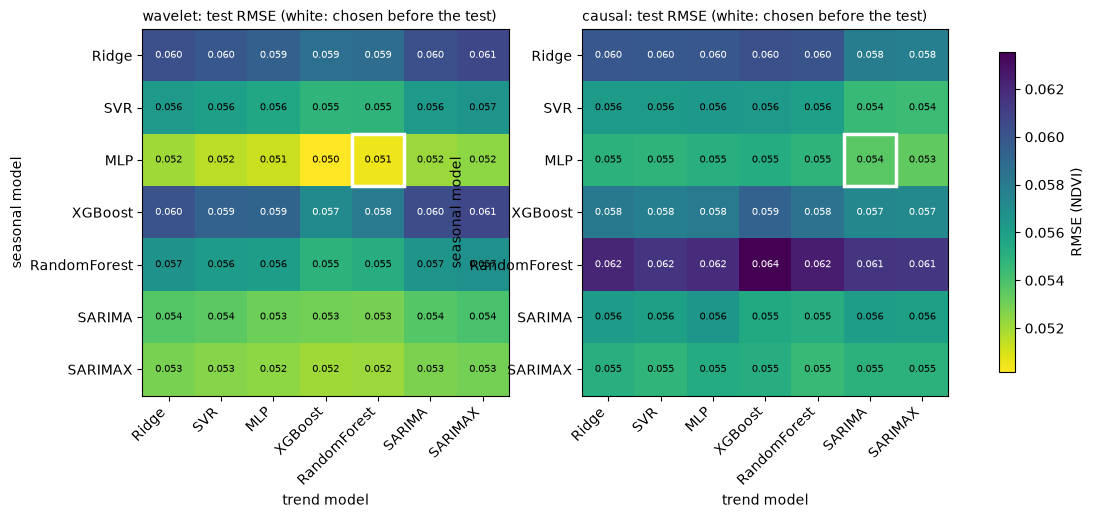

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
g_all = [last["grids"][(d, "window")] for d in ["wavelet", "causal"]]
vmin, vmax = min(g.min().min() for g in g_all), max(g.max().max() for g in g_all)
for ax, dec, g in zip(axes, ["wavelet", "causal"], g_all):
    im = ax.imshow(g.to_numpy(), cmap="viridis_r", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(ALL)), ALL, rotation=45, ha="right")
    ax.set_yticks(range(len(ALL)), ALL)
    ax.set_xlabel("trend model")
    ax.set_ylabel("seasonal model")
    s, t = last["chosen"][dec]
    ax.add_patch(plt.Rectangle((ALL.index(t) - 0.5, ALL.index(s) - 0.5), 1, 1,
                               fill=False, ec="white", lw=2.5))
    for i in range(len(ALL)):
        for j in range(len(ALL)):
            ax.text(j, i, f"{g.iloc[i, j]:.3f}", ha="center", va="center", fontsize=7,
                    color="white" if g.iloc[i, j] > (vmin + vmax) / 2 else "black")
    ax.set_title(f"{dec}: test RMSE (white: chosen before the test)", loc="left", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8, label="RMSE (NDVI)")
fig.savefig("../figures/09_pairings.png", dpi=150, bbox_inches="tight")
plt.show()

## Forecasts compared

Every forecast at every origin: each model fitted to NDVI directly, the chosen pairing of
each decomposition, **persistence** (last month's value) and **climatology** (the mean of
the calendar month over the months before the origin). Scores are RMSE, R² and MAE
(Hyndman and Koehler, 2006).

**Is a difference real?** The Diebold–Mariano test (Diebold and Mariano, 1995) asks whether
two forecasts' mean squared errors differ beyond chance, from the month-by-month difference
of their squared errors. Its variance uses the Newey–West estimator (Newey and West, 1987),
because errors of neighbouring months are correlated, and the statistic is referred to a
t distribution as Harvey et al. (1997) recommend for short samples. Every forecast is
compared with SARIMA, over the 36 test months and over the 180 months of all five windows
pooled; with many comparisons, p-values are adjusted by Holm's method (Holm, 1979). A
negative statistic means the forecast's errors are smaller than SARIMA's.

In [10]:
def all_forecasts(o, data=DATA, state=None, chosen=None):
    state, chosen = state or o["state"], chosen or o["chosen"]
    y = data[("direct", "original")]["target"]
    dates, cutoff = o["dates"], o["cutoff"]
    out = {f"direct {n}": forecast(("direct", "original"), n, state, cutoff, dates, data=data) for n in ALL}
    for dec in chosen:
        s, t = chosen[dec]
        out[f"{dec} pairing"] = (forecast((dec, "seasonal"), s, state, cutoff, dates, data=data)
                                 + forecast((dec, "trend"), t, state, cutoff, dates, data=data))
    past = y[y.index <= cutoff]
    out["persistence"] = data[("direct", "original")].loc[dates, "NDVI_lag1"]
    out["climatology"] = pd.Series(dates.month.map(past.groupby(past.index.month).mean()), index=dates)
    return out


def dm_test(e_model, e_ref):
    # negative statistic: the model's squared errors are smaller than the reference's
    d = np.asarray(e_model) ** 2 - np.asarray(e_ref) ** 2
    n = len(d)
    lags = int(np.floor(4 * (n / 100) ** (2 / 9)))
    u = d - d.mean()
    var = u @ u / n
    for k in range(1, lags + 1):
        var += 2 * (1 - k / (lags + 1)) * (u[k:] @ u[:-k]) / n
    stat = d.mean() / np.sqrt(var / n)
    return stat, 2 * stats.t.sf(abs(stat), n - 1)


def holm(p):
    p = pd.Series(p)
    order = p.sort_values().index
    adj = (p[order] * np.arange(len(p), 0, -1)).cummax().clip(upper=1)
    return adj.reindex(p.index)


fc = {label: all_forecasts(o) for label, o in origins.items()}
y_by = {label: ndvi[o["dates"]] for label, o in origins.items()}


def compare(fc, y_by, ref="direct SARIMA"):
    names = list(next(iter(fc.values())))
    test_y, test_f = y_by[TEST], fc[TEST]
    pooled_y = pd.concat(y_by.values())
    pooled = {n: pd.concat([fc[w][n] for w in fc]) for n in names}
    rows = []
    for n in names:
        rows.append(dict(
            forecast=n,
            test_RMSE=rmse(test_y, test_f[n]), test_R2=r2_score(test_y, test_f[n]),
            test_MAE=mean_absolute_error(test_y, test_f[n]),
            rolling_RMSE=np.mean([rmse(y_by[w], fc[w][n]) for w in fc]),
            rolling_R2=np.mean([r2_score(y_by[w], fc[w][n]) for w in fc]),
            windows_beating_ref=sum(rmse(y_by[w], fc[w][n]) < rmse(y_by[w], fc[w][ref]) for w in fc),
            dm_test=dm_test(test_y - test_f[n], test_y - test_f[ref]),
            dm_pooled=dm_test(pooled_y - pooled[n], pooled_y - pooled[ref])))
    t = pd.DataFrame(rows).set_index("forecast")
    others = t.index != ref
    for which in ["test", "pooled"]:
        t[f"DM_{which}"] = t[f"dm_{which}"].str[0]
        t[f"p_{which}"] = np.nan
        t.loc[others, f"p_{which}"] = holm(t.loc[others, f"dm_{which}"].str[1]).to_numpy()
    t["rolling_RMSE_vs_ref_%"] = 100 * (t.rolling_RMSE / t.loc[ref, "rolling_RMSE"] - 1)
    return t.drop(columns=["dm_test", "dm_pooled"]).sort_values("rolling_RMSE")


table = compare(fc, y_by)
print(table.round(4).to_string())
print("\nchosen pairings by window:")
for label, o in origins.items():
    print(f"  {label}: wavelet {' + '.join(o['chosen']['wavelet'])}, causal {' + '.join(o['chosen']['causal'])}")

                     test_RMSE  test_R2  test_MAE  rolling_RMSE  rolling_R2  windows_beating_ref  DM_test  p_test  DM_pooled  p_pooled  rolling_RMSE_vs_ref_%
forecast                                                                                                                                                     
wavelet pairing         0.0505   0.8968    0.0358        0.0415      0.9352                    5  -1.0197  1.0000    -1.6627    0.5888                -8.8004
direct SARIMAX          0.0541   0.8815    0.0356        0.0438      0.9292                    4  -1.3566  1.0000    -1.9111    0.4607                -3.6740
direct SARIMA           0.0556   0.8751    0.0363        0.0455      0.9228                    0      NaN     NaN        NaN       NaN                 0.0000
causal pairing          0.0536   0.8839    0.0373        0.0460      0.9217                    2  -0.6515  1.0000     0.1927    1.0000                 1.2254
direct MLP              0.0466   0.9123    0.0345   

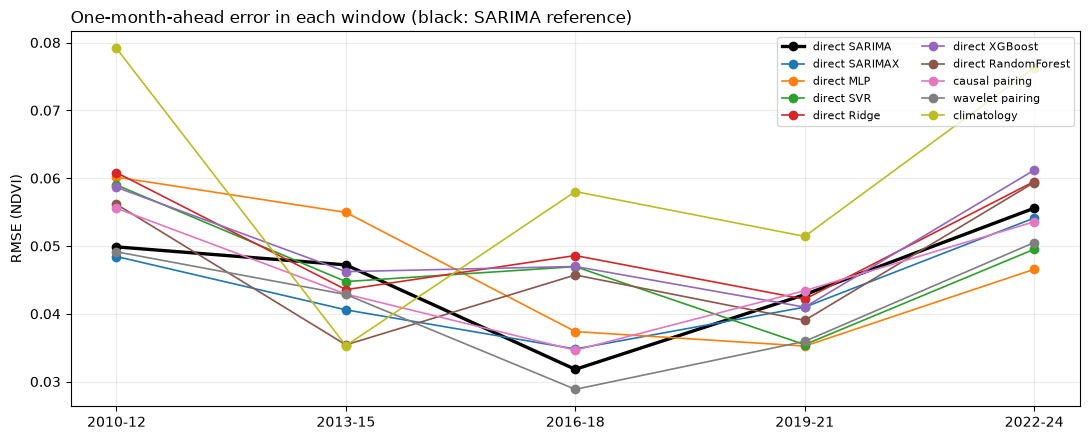

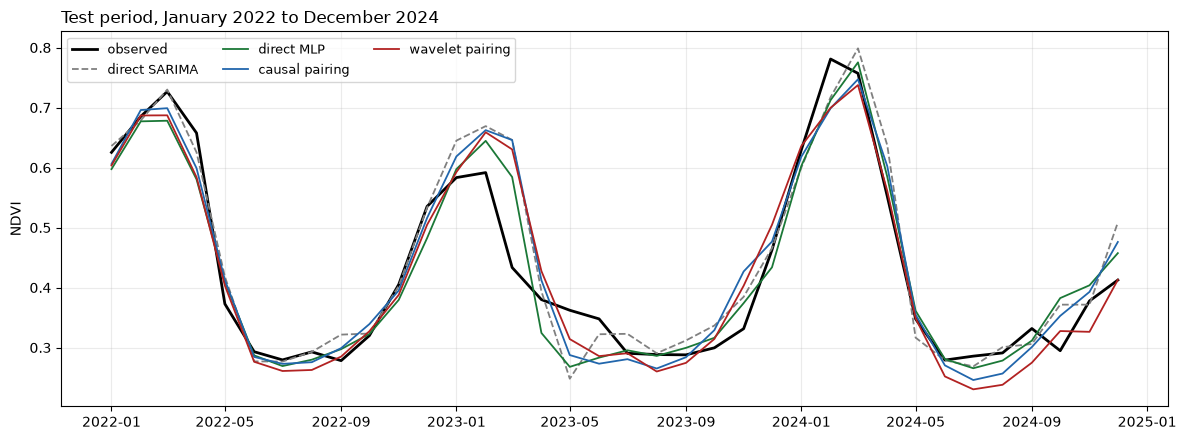

In [11]:
by_window = pd.DataFrame({label: {n: rmse(y_by[label], f[n]) for n in f} for label, f in fc.items()})
show = ["direct SARIMA", "direct SARIMAX", "direct MLP", "direct SVR", "direct Ridge",
        "direct XGBoost", "direct RandomForest", "causal pairing", "wavelet pairing", "climatology"]
fig, ax = plt.subplots(figsize=(11, 4.5))
for n in show:
    style = dict(lw=2.4, color="black") if n == "direct SARIMA" else dict(lw=1.2)
    ax.plot(by_window.columns, by_window.loc[n], marker="o", label=n, **style)
ax.set_ylabel("RMSE (NDVI)")
ax.grid(alpha=0.25)
ax.legend(ncol=2, fontsize=8, loc="upper right")
ax.set_title("One-month-ahead error in each window (black: SARIMA reference)", loc="left")
fig.tight_layout()
fig.savefig("../figures/09_rolling.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.5))
yt = y_by[TEST]
ax.plot(yt.index, yt, color="black", lw=2, label="observed")
for n, c, ls in [("direct SARIMA", "grey", "--"), ("direct MLP", "#1b7837", "-"),
                 ("causal pairing", "#2166ac", "-"), ("wavelet pairing", "firebrick", "-")]:
    ax.plot(yt.index, fc[TEST][n], color=c, ls=ls, lw=1.3, label=n)
ax.set_ylabel("NDVI")
ax.grid(alpha=0.25)
ax.legend(ncol=3, fontsize=9)
ax.set_title("Test period, January 2022 to December 2024", loc="left")
fig.tight_layout()
fig.savefig("../figures/09_test_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

## Noise floor

The seeded models refitted with 20 seeds at the test origin; a difference smaller than the
seed-to-seed spread is indistinguishable from refitting. Ridge, SVR and SARIMA are
deterministic.

In [12]:
def spread_over_seeds(make):
    r = [rmse(y_by[TEST], make(seed)) for seed in range(20)]
    return np.mean(r), np.std(r)


floor = []
st, cut, dates = last["state"], last["cutoff"], last["dates"]
for name in SEEDED:
    m, s = spread_over_seeds(lambda seed: forecast(("direct", "original"), name, st, cut, dates, seed))
    floor.append(dict(forecast=f"direct {name}", RMSE_mean=m, RMSE_sd=s))
for dec, (sm, tm) in last["chosen"].items():
    if sm in SEEDED or tm in SEEDED:
        m, s = spread_over_seeds(lambda seed: forecast((dec, "seasonal"), sm, st, cut, dates, seed)
                                 + forecast((dec, "trend"), tm, st, cut, dates, seed))
        floor.append(dict(forecast=f"{dec} pairing", RMSE_mean=m, RMSE_sd=s))
noise_floor = pd.DataFrame(floor).set_index("forecast")
print(noise_floor.round(4).to_string())

                     RMSE_mean  RMSE_sd
forecast                               
direct XGBoost          0.0594   0.0013
direct RandomForest     0.0587   0.0009
direct MLP              0.0468   0.0005
wavelet pairing         0.0506   0.0004
causal pairing          0.0539   0.0004


## Prediction intervals

A forecast for drought monitoring is more useful with a range. SARIMA gives one from its
own error model, which assumes Gaussian errors. For the other forecasts, a split-conformal
interval (Vovk et al., 2005; Lei et al., 2018) adds and subtracts the quantile of the
absolute out-of-fold errors before the origin. Its coverage guarantee assumes the errors are
exchangeable, which a time series only approximates (Barber et al., 2023), so the coverage
reached on the test period is the check.

In [13]:
rows = []
yt = y_by[TEST]
for level in [0.8, 0.95]:
    ci = sarima(DATA[("direct", "original")], st["orders"][("direct", "original")], cut, dates,
                exog=False, alpha=1 - level)
    lo, hi = ci.iloc[:, 0], ci.iloc[:, 1]
    rows.append(dict(forecast="direct SARIMA (model-based)", level=level,
                     coverage=((yt >= lo) & (yt <= hi)).mean(), mean_width=(hi - lo).mean()))
    for name in ["direct SARIMA", "direct MLP", "direct SVR", "direct XGBoost", "causal pairing", "wavelet pairing"]:
        if name.endswith("pairing"):
            dec = name.split()[0]
            s, t = last["chosen"][dec]
            past = last["oof"][(dec, "seasonal", s)] + last["oof"][(dec, "trend", t)]
        else:
            past = last["oof"][("direct", "original", name.split()[1])]
        r = (ndvi[last["valid"]] - past[last["valid"]]).abs()
        n = len(r)
        q = np.quantile(r, min(1, np.ceil((n + 1) * level) / n))
        p = fc[TEST][name]
        rows.append(dict(forecast=f"{name} (conformal)", level=level,
                         coverage=((yt >= p - q) & (yt <= p + q)).mean(), mean_width=2 * q))
intervals = pd.DataFrame(rows)
print(intervals.round(3).to_string(index=False))

                   forecast  level  coverage  mean_width
direct SARIMA (model-based)   0.80     0.750       0.103
  direct SARIMA (conformal)   0.80     0.750       0.106
     direct MLP (conformal)   0.80     0.833       0.115
     direct SVR (conformal)   0.80     0.806       0.124
 direct XGBoost (conformal)   0.80     0.722       0.112
 causal pairing (conformal)   0.80     0.722       0.099
wavelet pairing (conformal)   0.80     0.722       0.103
direct SARIMA (model-based)   0.95     0.889       0.157
  direct SARIMA (conformal)   0.95     0.917       0.186
     direct MLP (conformal)   0.95     0.972       0.191
     direct SVR (conformal)   0.95     0.972       0.193
 direct XGBoost (conformal)   0.95     0.889       0.210
 causal pairing (conformal)   0.95     0.944       0.188
wavelet pairing (conformal)   0.95     0.972       0.191


## What the forecasts rely on

Three views, at the test origin.

1. **Family importance.** Each family of predictors (own past, calendar, LST, SPEI, noise
   probe) is shuffled as one block, with the same row permutation for all its columns, and
   the rise in test RMSE is recorded, 50 shuffles. Shuffling one lag at a time would let
   correlated lags cover for one another and would create combinations of values that never
   occur (Strobl et al., 2008; Hooker et al., 2021); shuffling a whole family avoids both
   within the family. Importance is a property of the fitted model, not of the orchard
   (Fisher et al., 2019).
2. **Clock or weather.** LST follows the season closely, so a model may use it only as a
   clock. As in notebook 05, each model is refitted with LST as used, without LST, with LST
   replaced by its mean for the calendar month (the season only), and with LST replaced by
   its departure from that mean (the weather only); out-of-fold error on the validation
   folds before the test origin. If the climatology alone restores what removing LST costs,
   the model uses LST as a clock; if the anomaly does, as weather.
3. **SARIMAX coefficients.** The fitted coefficients of the climate regressors, with their
   p-values.

In [14]:
FAMILY = [("NDVI", "own past"), ("month", "calendar"), ("LST", "LST"), ("SPEI", "SPEI"), ("noise", "noise probe")]


def family(col):
    return next(f for prefix, f in FAMILY if col.startswith(prefix))


def family_importance(key, name, repeats=50):
    df = DATA[key]
    X, y = df.drop(columns="target"), df["target"]
    tr = df.index <= cut
    est = make_model(name, st["params"][(key, name)]).fit(X[tr], y[tr])
    Xt, yt_ = X.loc[dates], y.loc[dates]
    base = rmse(yt_, est.predict(Xt))
    rng = np.random.default_rng(SEED)
    out = {}
    for fam, cols in pd.Series(X.columns, index=X.columns).groupby(X.columns.map(family)):
        rises = []
        for _ in range(repeats):
            Xp = Xt.copy()
            Xp[list(cols)] = Xt[list(cols)].to_numpy()[rng.permutation(len(Xt))]
            rises.append(rmse(yt_, est.predict(Xp)) - base)
        out[fam] = max(0.0, np.mean(rises))
    s = pd.Series(out)
    return (s / s.sum()).rename(f"{'/'.join(key)} {name}")


def lst_variants(key, name):
    df = DATA[key]
    X, y = df.drop(columns="target"), df["target"]
    lst = [c for c in X.columns if c.startswith("LST")]
    errors = {}
    for variant in ["as used", "without LST", "climatology only", "anomaly only"]:
        preds = []
        for a, b, c in st["folds"]:
            tr, va = X.index <= a, (X.index >= b) & (X.index <= c)
            Xtr, Xva = X[tr].copy(), X[va].copy()
            if variant == "without LST":
                Xtr, Xva = Xtr.drop(columns=lst), Xva.drop(columns=lst)
            elif variant != "as used":
                for col in lst:
                    clim = Xtr[col].groupby(Xtr.index.month).mean()
                    ctr = Xtr.index.month.map(clim).to_numpy()
                    cva = Xva.index.month.map(clim).to_numpy()
                    if variant == "climatology only":
                        Xtr[col], Xva[col] = ctr, cva
                    else:
                        Xtr[col], Xva[col] = Xtr[col] - ctr, Xva[col] - cva
            est = make_model(name, st["params"][(key, name)]).fit(Xtr, y[tr])
            preds.append(pd.Series(est.predict(Xva), index=Xva.index))
        p = pd.concat(preds)
        errors[variant] = rmse(y[p.index], p)
    e = pd.Series(errors)
    return (100 * (e / e["as used"] - 1)).rename(f"{'/'.join(key)} {name}")


best_direct = min(MODELS, key=lambda n: last["direct_cv"][n])
explain = [(("direct", "original"), best_direct)]
for dec, (s, t) in last["chosen"].items():
    explain += [((dec, "seasonal"), s), ((dec, "trend"), t)]
explain = [(k, n) for k, n in dict.fromkeys(explain) if n in MODELS]

shares = pd.concat([family_importance(k, n) for k, n in explain], axis=1).fillna(0)
print("share of family importance, test period")
print(shares.round(3).to_string())

lst_effect = pd.concat([lst_variants(k, n) for k, n in explain], axis=1)
print("\nchange in validation RMSE (%) against LST as used")
print(lst_effect.round(1).to_string())

fit, _, _ = sarima_fit(DATA[("direct", "original")], st["orders"][("direct", "original")], cut, exog=True)
print("\ndirect SARIMAX coefficients, test origin")
print(pd.DataFrame({"coef": fit.params, "p": fit.pvalues}).round(4).to_string())

share of family importance, test period
             direct/original MLP  wavelet/seasonal MLP  wavelet/trend RandomForest  causal/seasonal MLP
LST                        0.220                 0.252                       0.000                0.245
SPEI                       0.018                 0.024                       0.001                0.018
calendar                   0.099                 0.046                       0.000                0.047
noise probe                0.005                 0.002                       0.000                0.003
own past                   0.657                 0.677                       0.999                0.687



change in validation RMSE (%) against LST as used
                  direct/original MLP  wavelet/seasonal MLP  wavelet/trend RandomForest  causal/seasonal MLP
as used                           0.0                   0.0                         0.0                  0.0
without LST                       1.6                   3.8                         3.6                  4.0
climatology only                  2.4                   4.1                         4.3                  4.2
anomaly only                     -1.4                  -4.7                        -3.6                 -1.2



direct SARIMAX coefficients, test origin
               coef       p
SPEI_6_lag2  0.0127  0.0013
LST_lag1    -0.0043  0.0040
ar.L1        0.7351  0.0000
ar.L2       -0.1770  0.0103
ar.S.L12    -0.2506  0.0003
ma.S.L12    -0.7350  0.0000
sigma2       0.0015  0.0000


## Sensitivity: composite timing

Notebook 02 found that about a fifth of a month's NDVI observation window, and a tenth of
its LST window, lies in the following month, because a composite is dated by the first day of
its window. Here each composite is instead assigned to the month in which its window
**ends**, so a monthly value uses only days up to the end of that month and no predictor
can see into the month it forecasts. The predictors are rebuilt with the same lags, and the
forecasts are repeated at every origin with the orders, hyperparameters and pairings already
chosen there. If the ranking of forecasts holds, the timing does not explain the result.
The wavelet pairing is left out: its components would have to be recomputed in notebook 02.

In [15]:
PATTERN = re.compile(r"^(NDVI|LST|SPEI_\d+)(?:_(Sm|Tm))?_(lag|roll)(\d+)$")
raw = {
    "NDVI": (pd.read_csv("../data/raw/orchard_ndvi_16day.csv", parse_dates=["date"])
               .set_index("date")["NDVI"].interpolate(), 15),
    "LST": (pd.read_csv("../data/raw/orchard_lst_8day.csv", parse_dates=["date"])
              .set_index("date")["LST"].interpolate(), 7),
}
monthly = pd.read_csv("../data/raw/orchard_monthly.csv", index_col="date", parse_dates=True)
series = {v: s.set_axis(s.index + pd.Timedelta(days=days)).resample("MS").mean()
          for v, (s, days) in raw.items()}
series.update({c: monthly[c] for c in monthly.columns if c.startswith("SPEI")})


def part(var, which):
    s = series[var]
    trend = s.rolling(12).mean()
    return {None: s, "Tm": trend, "Sm": s - trend}[which]


def rebuild(key):
    df = DATA[key]
    out = pd.DataFrame(index=df.index)
    for c in df.columns.drop("target"):
        m = PATTERN.match(c)
        if m is None:  # calendar and noise probe
            out[c] = df[c]
            continue
        s = part(m[1], m[2]).reindex(series["NDVI"].index)
        k = int(m[4])
        out[c] = (s.shift(k) if m[3] == "lag" else s.shift(1).rolling(k).mean()).reindex(df.index)
    which = {"original": None, "seasonal": "Sm", "trend": "Tm"}[key[1]]
    out["target"] = part("NDVI", which).reindex(df.index)
    return out


ENDED = {k: rebuild(k) for k in DATA if k[0] != "wavelet"}
assert not any(df.isna().any().any() for df in ENDED.values())
y_end = ENDED[("direct", "original")]["target"]
print(f"NDVI by window end vs by window start: r = {y_end.corr(ndvi):.3f}, "
      f"mean shift {(y_end - ndvi).mean():+.4f}\n")

fc_end = {label: all_forecasts(o, data=ENDED, chosen={"causal": o["chosen"]["causal"]})
          for label, o in origins.items()}
y_end_by = {label: y_end[o["dates"]] for label, o in origins.items()}
table_end = compare(fc_end, y_end_by)
print(table_end[["test_RMSE", "rolling_RMSE", "rolling_RMSE_vs_ref_%", "windows_beating_ref",
                 "DM_pooled", "p_pooled"]].round(4).to_string())

NDVI by window end vs by window start: r = 0.951, mean shift +0.0013



                     test_RMSE  rolling_RMSE  rolling_RMSE_vs_ref_%  windows_beating_ref  DM_pooled  p_pooled
forecast                                                                                                     
direct SARIMA           0.0514        0.0413                 0.0000                    0        NaN       NaN
direct SARIMAX          0.0500        0.0413                 0.1837                    3    -0.2314    1.0000
causal pairing          0.0482        0.0421                 2.0798                    2     0.0839    1.0000
direct RandomForest     0.0514        0.0439                 6.2796                    2     0.7906    1.0000
direct MLP              0.0409        0.0449                 8.8931                    2     0.9212    1.0000
direct XGBoost          0.0507        0.0460                11.3989                    1     1.7875    0.4532
direct SVR              0.0484        0.0470                13.8329                    2     1.6926    0.4614
direct Rid

## Summary

1. **The reference is well specified.** The rule chose SARIMA(2,0,0)(1,1,1)₁₂ at the test
   origin, and similar orders at every origin; the residuals of the original series show no
   remaining autocorrelation at any origin (Ljung–Box p ≥ 0.22).
2. **No forecast beats SARIMA beyond chance.** Over the 180 months of the five windows, no
   difference from SARIMA is significant after Holm's correction (Diebold–Mariano), except
   that persistence is worse. Random Forest, SVR and the MLP are 3–4% worse than SARIMA on
   average, XGBoost and Ridge 12%, climatology 32% and persistence 125%; SARIMAX is 4% better
   in four windows of five, not significantly.
3. **The MLP improves as the training record grows.** It is the most accurate forecast in
   the 2022–2024 drought (RMSE 0.047 against 0.056, R² 0.91 against 0.88) and beats SARIMA
   in 2019–2021, but is worse than SARIMA in the first three windows, where it was trained
   on seven to thirteen years (RMSE 0.060 against 0.050 in 2010–2012).
4. **The seasonal model decides the pairing.** Changing the seasonal model moves the error
   by about 0.010 on average; changing the trend model by 0.001–0.002, four to ten times
   less. Over one month the trend barely moves.
5. **The causal pairing matches SARIMA** (1% worse on average). The wavelet pairing is 9%
   better in every window but uses later months, and is not significant either.
6. **Composite timing does not explain the results.** With each composite assigned to the
   month its window ends, SARIMA and SARIMAX lead and every learned model is worse than
   SARIMA, Ridge significantly.
7. **LST is the climate signal the models use, as weather.** It carries 22–25% of the MLPs'
   family importance against at most 2.4% for SPEI. Replacing LST by its monthly mean does
   not restore what removing it costs; replacing it by its departure from that mean does,
   and more. In SARIMAX, warmer LST lowers next month's NDVI (−0.004 per °C, p = 0.004) and
   wetter SPEI-6 raises it (+0.013 per unit, p = 0.001).
8. **Intervals.** SARIMA's 95% interval covered 89% of the drought months; the conformal
   intervals covered 89–97%.

## Limitations

1. **One site, one horizon.** One orchard of about ten MODIS pixels, and one-month-ahead
   forecasts only. Longer horizons, where SARIMA's seasonal structure and the learned models
   may rank differently, and a second site are needed before generalising.
2. **Small differences.** The differences between the best forecasts are a few per cent of
   RMSE. The Diebold–Mariano tests and the window-by-window counts above say which are
   distinguishable from chance; differences they do not support should not be reported as
   improvements.
3. **The wavelet pairing sees later months.** Its components come from a two-sided filter
   (notebook 02), so its accuracy is not available to a real forecast (Du et al., 2017;
   Quilty and Adamowski, 2018). It is reported to measure that gap, not as a candidate.
4. **The causal decomposition is crude.** A trailing mean lags turning points by about half
   a year. A boundary-corrected wavelet (Quilty and Adamowski, 2018) might separate the
   components better without looking ahead; it was not built here.
5. **Selection effects.** Each pairing is chosen among 49 on the validation months before
   its origin; the chosen one is the best on those months, so its validation error is
   optimistic. Its forecast window was not used in the choice, so the window errors are not.
6. **Order selection is a rule, not an optimum.** A wider grid or another criterion could
   choose other orders. The rule was fixed before any result was seen and is the same at
   every origin; residual checks are reported above.
7. **Conformal intervals assume exchangeable errors**, which seasonal errors are not
   (Barber et al., 2023); their coverage is checked on the test period, not guaranteed.
8. **Importance is not causation.** Family importance and the LST variants describe what
   the fitted models use (Fisher et al., 2019). Climate predictors are measured at 1 km
   (LST) and 0.5° (SPEI), coarser than the orchard (notebook 02).

## Saving

In [16]:
def plain(v):
    return v.item() if hasattr(v, "item") else v


json.dump({label: {"orders": {"|".join(k): {**v, "order": list(v["order"]), "seasonal_order": list(v["seasonal_order"])}
                              for k, v in o["state"]["orders"].items()},
                   "params": {"|".join((*k[0], k[1])): {p: plain(x) for p, x in v.items()}
                              for k, v in o["state"]["params"].items()},
                   "chosen": {d: list(v) for d, v in o["chosen"].items()}}
           for label, o in origins.items()},
          open("../results/09_origins.json", "w"), indent=1, default=str)
pd.concat({f"{label}|{d}|{w}": g for label, o in origins.items() for (d, w), g in o["grids"].items()}
          ).to_csv("../results/09_pairings.csv")
table.to_csv("../results/09_comparison.csv")
by_window.to_csv("../results/09_rmse_by_window.csv")
spread.to_csv("../results/09_component_spread.csv", index=False)
noise_floor.to_csv("../results/09_noise_floor.csv")
intervals.to_csv("../results/09_intervals.csv", index=False)
shares.to_csv("../results/09_importance_families.csv")
lst_effect.to_csv("../results/09_lst_variants.csv")
table_end.to_csv("../results/09_comparison_window_end.csv")
pd.DataFrame({n: pd.concat([fc[w][n] for w in fc]) for n in fc[TEST]}).to_csv("../results/09_forecasts.csv")
print("saved")

saved


## References

- Akaike, H. (1974). A new look at the statistical model identification. IEEE Transactions on Automatic Control, 19(6), 716–723.
- Barber, R. F., Candès, E. J., Ramdas, A. & Tibshirani, R. J. (2023). Conformal prediction beyond exchangeability. The Annals of Statistics, 51(2), 816–845.
- Bergmeir, C. & Benítez, J. M. (2012). On the use of cross-validation for time series predictor evaluation. Information Sciences, 191, 192–213.
- Bergmeir, C., Hyndman, R. J. & Koo, B. (2018). A note on the validity of cross-validation for evaluating autoregressive time series prediction. Computational Statistics & Data Analysis, 120, 70–83.
- Bergstra, J. & Bengio, Y. (2012). Random search for hyper-parameter optimization. Journal of Machine Learning Research, 13, 281–305.
- Box, G. E. P., Jenkins, G. M., Reinsel, G. C. & Ljung, G. M. (2015). Time Series Analysis: Forecasting and Control (5th ed.). Wiley.
- Breiman, L. (2001). Random forests. Machine Learning, 45(1), 5–32.
- Chen, T. & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 785–794.
- Cleveland, R. B., Cleveland, W. S., McRae, J. E. & Terpenning, I. (1990). STL: A seasonal-trend decomposition procedure based on loess. Journal of Official Statistics, 6(1), 3–73.
- Cortes, C. & Vapnik, V. (1995). Support-vector networks. Machine Learning, 20(3), 273–297.
- Dickey, D. A. & Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. Journal of the American Statistical Association, 74(366), 427–431.
- Diebold, F. X. & Mariano, R. S. (1995). Comparing predictive accuracy. Journal of Business & Economic Statistics, 13(3), 253–263.
- Drucker, H., Burges, C. J. C., Kaufman, L., Smola, A. & Vapnik, V. (1997). Support vector regression machines. Advances in Neural Information Processing Systems, 9, 155–161.
- Du, K., Zhao, Y. & Lei, J. (2017). The incorrect usage of singular spectral analysis and discrete wavelet transform in hybrid models to predict hydrological time series. Journal of Hydrology, 552, 44–51. https://doi.org/10.1016/j.jhydrol.2017.06.019
- Fisher, A., Rudin, C. & Dominici, F. (2019). All models are wrong, but many are useful: learning a variable's importance by studying an entire class of prediction models simultaneously. Journal of Machine Learning Research, 20(177), 1–81.
- Harvey, D., Leybourne, S. & Newbold, P. (1997). Testing the equality of prediction mean squared errors. International Journal of Forecasting, 13(2), 281–291.
- Hewamalage, H., Bergmeir, C. & Bandara, K. (2021). Recurrent neural networks for time series forecasting: current status and future directions. International Journal of Forecasting, 37(1), 388–427.
- Hoerl, A. E. & Kennard, R. W. (1970). Ridge regression: biased estimation for nonorthogonal problems. Technometrics, 12(1), 55–67.
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. Scandinavian Journal of Statistics, 6(2), 65–70.
- Hooker, G., Mentch, L. & Zhou, S. (2021). Unrestricted permutation forces extrapolation: variable importance requires at least one more model, or there is no free variable importance. Statistics and Computing, 31, 82.
- Hyndman, R. J. & Khandakar, Y. (2008). Automatic time series forecasting: the forecast package for R. Journal of Statistical Software, 27(3), 1–22.
- Hyndman, R. J. & Koehler, A. B. (2006). Another look at measures of forecast accuracy. International Journal of Forecasting, 22(4), 679–688.
- Kwiatkowski, D., Phillips, P. C. B., Schmidt, P. & Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root. Journal of Econometrics, 54(1–3), 159–178.
- Lei, J., G'Sell, M., Rinaldo, A., Tibshirani, R. J. & Wasserman, L. (2018). Distribution-free predictive inference for regression. Journal of the American Statistical Association, 113(523), 1094–1111.
- Liu, D. C. & Nocedal, J. (1989). On the limited memory BFGS method for large scale optimization. Mathematical Programming, 45, 503–528.
- Ljung, G. M. & Box, G. E. P. (1978). On a measure of lack of fit in time series models. Biometrika, 65(2), 297–303.
- Makridakis, S., Spiliotis, E. & Assimakopoulos, V. (2018). Statistical and machine learning forecasting methods: concerns and ways forward. PLoS ONE, 13(3), e0194889.
- Newey, W. K. & West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. Econometrica, 55(3), 703–708.
- Quilty, J. & Adamowski, J. (2018). Addressing the incorrect usage of wavelet-based hydrological and water resources forecasting models for real-world applications with best practices and a new forecasting framework. Journal of Hydrology, 563, 336–353. https://doi.org/10.1016/j.jhydrol.2018.05.003
- Rumelhart, D. E., Hinton, G. E. & Williams, R. J. (1986). Learning representations by back-propagating errors. Nature, 323, 533–536.
- Said, S. E. & Dickey, D. A. (1984). Testing for unit roots in autoregressive-moving average models of unknown order. Biometrika, 71(3), 599–607.
- Smola, A. J. & Schölkopf, B. (2004). A tutorial on support vector regression. Statistics and Computing, 14(3), 199–222.
- Strobl, C., Boulesteix, A.-L., Kneib, T., Augustin, T. & Zeileis, A. (2008). Conditional variable importance for random forests. BMC Bioinformatics, 9, 307.
- Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: an analysis and review. International Journal of Forecasting, 16(4), 437–450.
- Vovk, V., Gammerman, A. & Shafer, G. (2005). Algorithmic Learning in a Random World. Springer.
- Wang, X., Smith, K. & Hyndman, R. (2006). Characteristic-based clustering for time series data. Data Mining and Knowledge Discovery, 13(3), 335–364.
- Zhang, G. P. (2003). Time series forecasting using a hybrid ARIMA and neural network model. Neurocomputing, 50, 159–175.